# 01 Data audit
First look at the fault-free AHU file. Check the timestamp column name and which signals actually vary.

In [11]:
import sys
sys.path.append("..")   
# lets the notebook find ahu_oa in the project root
import matplotlib.pyplot as plt
from ahu_oa import loading

df = loading.load_ahu_csv('../data/AHU_annual.csv')  # add time_col='...' once checked
df.shape

(525540, 30)

In [12]:
loading.audit_ahu(df)
time_col='Datetime'

Occupied hours only (`SYS_CTL == 1`): does the supply fan speed vary, and does the command track it?

In [13]:
occ = df[loading.occupied_mask(df)]
occ[['SF_CS', 'SF_SPD', 'SF_WAT', 'SA_Ls']].describe()

,SF_CS,SF_SPD,SF_WAT,SA_Ls
count,278682.000000,2.786820e+05,2.786820e+05,278682.000000
mean,0.728938,9.000000e-01,5.935688e+02,263455.219849
std,0.087061,5.551125e-16,1.744241e+02,41168.008719
min,0.000000,9.000000e-01,-8.874670e-12,-0.335534
25%,0.704071,9.000000e-01,5.139885e+02,260521.835638
50%,0.737952,9.000000e-01,5.735271e+02,281221.479112
75%,0.772226,9.000000e-01,6.865947e+02,281383.300454
max,1.000000,9.000000e-01,1.612949e+03,535149.991778


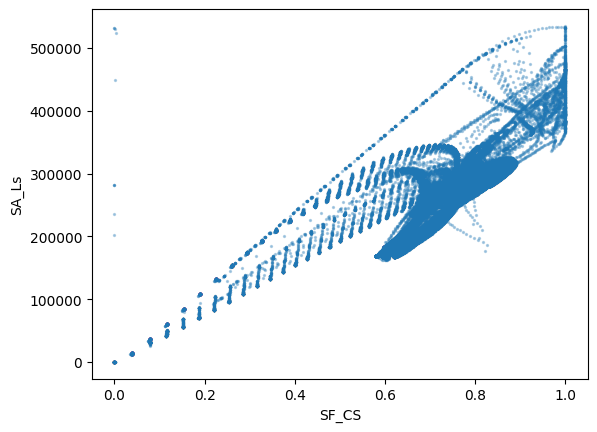

In [14]:
occ.plot.scatter(x='SF_CS', y='SA_Ls', s=2, alpha=0.3)
plt.show()